# 05 · Modelos y validación
**Proyecto Integrador ML2 — Segunda entrega · Predicción de la TRM**

**Objetivo (rúbricas 7.2, 7.3 y 7.4).** Entrenar la línea base de la Entrega 1 y los tres boosting con y sin variables macro, con **validación anidada**, **solo con el desarrollo**; contrastar las hipótesis H1–H4 del EDA; y **congelar** la configuración antes de abrir el test en el notebook 06.

**Diseño (contrato con la Entrega 1):**

| Rol | Modelo | Variables |
|---|---|---|
| Línea base (única) | Regresión lineal (`StandardScaler` + `LinearRegression`) | Rezagos 1, 5 y 10 de la TRM |
| Avanzados | LightGBM, CatBoost, XGBoost | **Solo TRM** (3 rezagos) y **TRM + macro** (+ Brent, DXY, diferencial) → 6 configuraciones |

Métricas: **RMSE en pesos** (principal), MAE en pesos y R² sobre retornos.

**Reglas fijadas antes de ver resultados:**
1. Los modelos se comparan **dentro de cada corte**, en el mismo periodo, porque el EDA (E3) mostró que la dificultad cambia mucho entre periodos.
2. **Mejor modelo** = la configuración de boosting con **menor RMSE medio** en los 5 cortes; si hay empate a dos decimales, la de menor desviación. Se compara siempre contra la línea base.
3. "Las macro aportan" en un algoritmo si su versión TRM + macro tiene menor RMSE que la versión solo TRM **en al menos 4 de 5 cortes**. Si es en 2 o 3, el aporte es inestable.

In [1]:
import sys, json, time, hashlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
import joblib

from src import config as cfg
from src.validacion import cortes_walk_forward, tabla_cortes, metricas
from src.modelos import ESPACIOS, JUSTIFICACION_ESPACIOS, evaluar_walk_forward, ajustar_final
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)
assert (dev["muestra"] == "desarrollo").all()          # el test no entra en este notebook
del datos
CONFIGS = {f"{m} · {c}": (m, v) for m in cfg.MODELOS_BOOSTING for c, v in cfg.CONJUNTOS.items()}
print(f"Desarrollo: {len(dev):,} días | configuraciones de boosting: {list(CONFIGS)}")

Desarrollo: 4,320 días | configuraciones de boosting: ['LightGBM · solo_trm', 'LightGBM · trm_macro', 'CatBoost · solo_trm', 'CatBoost · trm_macro', 'XGBoost · solo_trm', 'XGBoost · trm_macro']


## 1. Figura 2: el flujo completo y por qué no hay fuga

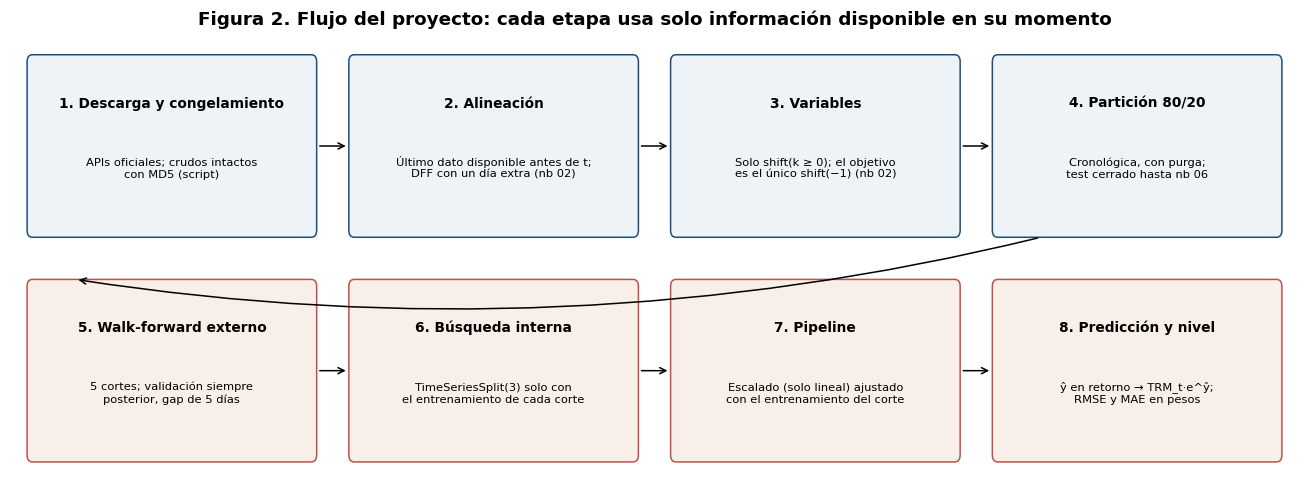

In [2]:
etapas = [
    ("1. Descarga y congelamiento", "APIs oficiales; crudos intactos\ncon MD5 (script)"),
    ("2. Alineación", "Último dato disponible antes de t;\nDFF con un día extra (nb 02)"),
    ("3. Variables", "Solo shift(k ≥ 0); el objetivo\nes el único shift(−1) (nb 02)"),
    ("4. Partición 80/20", "Cronológica, con purga;\ntest cerrado hasta nb 06"),
    ("5. Walk-forward externo", "5 cortes; validación siempre\nposterior, gap de 5 días"),
    ("6. Búsqueda interna", "TimeSeriesSplit(3) solo con\nel entrenamiento de cada corte"),
    ("7. Pipeline", "Escalado (solo lineal) ajustado\ncon el entrenamiento del corte"),
    ("8. Predicción y nivel", "ŷ en retorno → TRM_t·e^ŷ;\nRMSE y MAE en pesos"),
]
fig, eje = plt.subplots(figsize=(12, 4.6)); eje.axis("off")
for i, (tit, txt) in enumerate(etapas):
    x, yb = (i % 4) * 3.0, 1.6 if i < 4 else 0.0
    eje.add_patch(FancyBboxPatch((x, yb), 2.6, 1.2, boxstyle="round,pad=0.05",
                                 fc="#eef3f8" if i < 4 else "#f8efe8", ec=COLORES[0] if i < 4 else COLORES[1]))
    eje.text(x + 1.3, yb + 0.88, tit, ha="center", fontsize=9, fontweight="bold")
    eje.text(x + 1.3, yb + 0.38, txt, ha="center", fontsize=7.5)
    if i % 4 < 3:
        eje.annotate("", xy=(x + 2.95, yb + 0.6), xytext=(x + 2.65, yb + 0.6), arrowprops=dict(arrowstyle="->"))
eje.annotate("", xy=(0.4, 1.25), xytext=(9.4, 1.55), arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.1"))
eje.set(xlim=(-0.2, 11.8), ylim=(-0.2, 3.0))
eje.set_title("Figura 2. Flujo del proyecto: cada etapa usa solo información disponible en su momento", fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig02_pipeline"); plt.show()

## 2. Esquema de validación anidada
- **Bucle externo, para medir el desempeño:** `TimeSeriesSplit(n_splits=5, gap=5)` sobre el desarrollo. La ventana de entrenamiento crece y la validación de cada corte (720 días) es siempre posterior, separada por 5 días.
- **Bucle interno, para elegir los hiperparámetros:** dentro del entrenamiento de cada corte, `TimeSeriesSplit(3, gap=5)` y `RandomizedSearchCV` con 15 combinaciones (semilla 42), minimizando el error cuadrático en retornos. Es la validación cruzada de series de tiempo prometida en la Entrega 1.

Como el bloque externo nunca participa en la elección de hiperparámetros, su error es una estimación honesta.

In [3]:
cortes = cortes_walk_forward(len(dev))
for tr, va in cortes:
    assert tr.max() + cfg.GAP < va.min()                 # validación posterior, con separación
tcortes = tabla_cortes(dev["fecha"], cortes)
guardar_tabla(tcortes, "tab05a_cortes")
display(tcortes)

,entrena_desde,entrena_hasta,filas_entrenamiento,valida_desde,valida_hasta,filas_validacion
corte,,,,,,
1,2003-12-17,2006-12-15,715,2006-12-23,2010-01-09,720
2,2003-12-17,2009-12-31,1435,2010-01-13,2013-01-23,720
3,2003-12-17,2013-01-15,2155,2013-01-24,2016-02-05,720
4,2003-12-17,2016-01-29,2875,2016-02-06,2019-02-21,720
5,2003-12-17,2019-02-13,3595,2019-02-22,2022-03-01,720


## 3. Cambios frente a la Entrega 1 y su motivo

In [4]:
cambios = pd.DataFrame([
    ["Variable objetivo", "Precio diario de la TRM (nivel)", "Retorno ln(TRM_{t+1}/TRM_t); nivel reconstruido para el error en pesos",
     "Niveles no estacionarios (E1); techo de extrapolación de los árboles (nb 04, Figura 3)"],
    ["Variables", "Rezagos 1, 5, 10 de la TRM; petróleo; diferencial Banrep−Fed; DXY", "Las mismas, expresadas en retornos; el diferencial en nivel",
     "Coherencia con el objetivo en retornos; los árboles tampoco extrapolan en las variables"],
    ["Petróleo", "WTI o Brent", "Solo Brent", "Casi colineales; el crudo colombiano se referencia al Brent; el WTI fue negativo en abril de 2020"],
    ["Métricas", "RMSE (principal), MAE y R²", "Las mismas; el R² se calcula sobre retornos",
     "El R² en niveles da 0,99 incluso copiando la TRM de hoy (nb 04)"],
    ["Alineación", "\"Forward-fill estrictamente hacia atrás\"", "Último dato estrictamente anterior a t; DFF con un día extra",
     "Precisión: Brent y DXY cierran después del mercado colombiano; la DFF se publica al día siguiente"],
    ["Validación", "Partición cronológica + CV temporal para hiperparámetros", "La misma, anidada en un walk-forward de 5 cortes",
     "Rúbrica 7.4: validación anidada y resultados con variabilidad"],
    ["Comparación", "Tres boosting con macro frente a la línea base", "Tres boosting con y sin macro frente a la línea base",
     "Separa el efecto del algoritmo del efecto de las variables macro"],
], columns=["tema", "Entrega 1", "Entrega 2", "motivo"]).set_index("tema")
guardar_tabla(cambios, "tab05b_cambios_entrega1")
display(cambios)

,Entrega 1,Entrega 2,motivo
tema,,,
Variable objetivo,Precio diario de la TRM (nivel),Retorno ln(TRM_{t+1}/TRM_t); nivel reconstruid...,Niveles no estacionarios (E1); techo de extrap...
Variables,"Rezagos 1, 5, 10 de la TRM; petróleo; diferenc...","Las mismas, expresadas en retornos; el diferen...",Coherencia con el objetivo en retornos; los ár...
Petróleo,WTI o Brent,Solo Brent,Casi colineales; el crudo colombiano se refere...
Métricas,"RMSE (principal), MAE y R²",Las mismas; el R² se calcula sobre retornos,"El R² en niveles da 0,99 incluso copiando la T..."
Alineación,"""Forward-fill estrictamente hacia atrás""",Último dato estrictamente anterior a t; DFF co...,Precisión: Brent y DXY cierran después del mer...
Validación,Partición cronológica + CV temporal para hiper...,"La misma, anidada en un walk-forward de 5 cortes",Rúbrica 7.4: validación anidada y resultados c...
Comparación,Tres boosting con macro frente a la línea base,Tres boosting con y sin macro frente a la líne...,Separa el efecto del algoritmo del efecto de l...


## 4. Tabla 4: espacios de búsqueda y su justificación

In [5]:
t4 = pd.DataFrame({m: {k.replace("modelo__", ""): str(v) for k, v in e.items()} for m, e in ESPACIOS.items()})
guardar_tabla(t4, "tab04b_espacios_busqueda")
display(t4)
display(pd.Series(JUSTIFICACION_ESPACIOS, name="justificación").to_frame())

,LightGBM,CatBoost,XGBoost
n_estimators,"[100, 200, 400, 800]",NaN,"[100, 200, 400, 800]"
learning_rate,"[0.01, 0.03, 0.05, 0.1]","[0.01, 0.03, 0.05, 0.1]","[0.01, 0.03, 0.05, 0.1]"
max_depth,"[2, 3, 4, 6]",NaN,"[2, 3, 4, 6]"
num_leaves,"[4, 8, 15, 31]",NaN,NaN
min_child_samples,"[20, 50, 100, 200]",NaN,NaN
subsample,"[0.6, 0.8, 1.0]","[0.6, 0.8, 1.0]","[0.6, 0.8, 1.0]"
colsample_bytree,"[0.6, 0.8, 1.0]",NaN,"[0.6, 0.8, 1.0]"
reg_lambda,"[0.0, 1.0, 5.0, 10.0]",NaN,"[0.0, 1.0, 5.0, 10.0]"
iterations,NaN,"[100, 200, 400, 800]",NaN
depth,NaN,"[2, 3, 4, 6]",NaN


,justificación
número de árboles (100–800),Se combina con la tasa de aprendizaje: tasas b...
"tasa de aprendizaje (0,01–0,1)",Tasas bajas generalizan mejor cuando la señal ...
profundidad máxima (2–6),La relación en la media es casi lineal (E9) y ...
mínimo de observaciones por hoja (20–200) / peso mínimo (1–20),Evita reglas basadas en pocos días extremos (E...
"submuestreo de filas y columnas (0,6–1,0)",Reduce la varianza y la dependencia de una sol...
regularización L2 (0–10),"Encoge las predicciones hacia cero, lo prudent..."


## 5. Línea base y validación anidada de las 6 configuraciones

In [6]:
resultados, predicciones, hiper = {}, {}, {}
t0 = time.perf_counter()
m, p, h = evaluar_walk_forward(dev, cfg.VARS_TRM, "lineal", cortes)
resultados["Línea base (lineal)"], predicciones["Línea base (lineal)"] = m, p
for nombre, (algoritmo, variables) in CONFIGS.items():
    m, p, h = evaluar_walk_forward(dev, variables, algoritmo, cortes)
    resultados[nombre], predicciones[nombre], hiper[nombre] = m, p, h
print(f"Validación anidada completa en {time.perf_counter() - t0:.0f} s")

por_corte = pd.concat({k: v.set_index("corte") for k, v in resultados.items()}, names=["modelo", "corte"])
guardar_tabla(por_corte.drop(columns="segundos"), "tab05c_metricas_por_corte")   # el tiempo varía entre corridas
pd.concat({k: v for k, v in predicciones.items()}, names=["modelo", "i"]).reset_index(level=0).to_csv(
    cfg.DATA_PROC / "predicciones_validacion.csv", index=False)

Validación anidada completa en 13 s


## 6. Tabla 5: resultados en validación (media ± desviación en los 5 cortes)

In [7]:
base = resultados["Línea base (lineal)"].set_index("corte")
filas = []
for nombre, r in resultados.items():
    r = r.set_index("corte")
    filas.append({"modelo": nombre,
                  "rmse_media": r["rmse_pesos"].mean(), "rmse_desv": r["rmse_pesos"].std(),
                  "mae_media": r["mae_pesos"].mean(), "mae_desv": r["mae_pesos"].std(),
                  "r2_media": r["r2_retornos"].mean(), "r2_desv": r["r2_retornos"].std(),
                  "cortes_con_r2_positivo": int((r["r2_retornos"] > 0).sum()),
                  "cortes_que_gana_a_linea_base_rmse": int((r["rmse_pesos"] < base["rmse_pesos"]).sum())
                                                       if nombre != "Línea base (lineal)" else np.nan})
t5 = pd.DataFrame(filas).set_index("modelo")
guardar_tabla(t5, "tab05_validacion")
display(t5)
print("R² sobre retornos por corte:")
display(por_corte["r2_retornos"].unstack("corte"))
print("RMSE en pesos por corte:")
display(por_corte["rmse_pesos"].unstack("corte"))

,rmse_media,rmse_desv,mae_media,mae_desv,r2_media,r2_desv,cortes_con_r2_positivo,cortes_que_gana_a_linea_base_rmse
modelo,,,,,,,,
Línea base (lineal),20.8334,7.0017,14.7730,5.0004,0.0193,0.0165,4,NaN
LightGBM · solo_trm,20.7658,6.8745,14.8361,4.9399,0.0175,0.0097,5,3.0000
LightGBM · trm_macro,20.7742,6.8528,14.7936,4.9338,0.0181,0.0126,5,2.0000
CatBoost · solo_trm,20.7064,6.8619,14.7742,4.9575,0.0249,0.0102,5,4.0000
CatBoost · trm_macro,20.7679,6.7921,14.7864,4.8880,0.0179,0.0213,4,2.0000
XGBoost · solo_trm,20.8052,6.8463,14.8285,4.9323,0.0160,0.0211,3,3.0000
XGBoost · trm_macro,20.9382,6.7554,14.9043,4.8618,-0.0022,0.0291,2,1.0000


R² sobre retornos por corte:


corte,1,2,3,4,5
modelo,,,,,
Línea base (lineal),-0.0021,0.0317,0.0220,0.0376,0.0075
LightGBM · solo_trm,0.0057,0.0091,0.0211,0.0290,0.0226
LightGBM · trm_macro,0.0107,0.0157,0.0023,0.0322,0.0293
CatBoost · solo_trm,0.0098,0.0329,0.0210,0.0252,0.0354
CatBoost · trm_macro,0.0083,0.0195,-0.0126,0.0316,0.0425
XGBoost · solo_trm,-0.0062,0.0313,-0.0064,0.0231,0.0384
XGBoost · trm_macro,-0.0191,-0.0120,-0.0318,0.0096,0.0425


RMSE en pesos por corte:


corte,1,2,3,4,5
modelo,,,,,
Línea base (lineal),22.1034,9.9055,20.3742,22.4510,29.3327
LightGBM · solo_trm,21.9182,10.0104,20.2945,22.5578,29.0481
LightGBM · trm_macro,21.8683,9.9831,20.5379,22.5152,28.9665
CatBoost · solo_trm,21.8736,9.8928,20.3254,22.5873,28.8529
CatBoost · trm_macro,21.8898,9.9678,20.7225,22.5189,28.7403
XGBoost · solo_trm,22.0672,9.8979,20.6597,22.6206,28.7807
XGBoost · trm_macro,22.2095,10.1123,20.9131,22.7412,28.7147


**Lectura de la Tabla 5:**
- **Todos los modelos quedan prácticamente empatados.** El RMSE medio va de **20,71 a 20,94 pesos**: menos de 0,25 pesos de diferencia entre el mejor y el peor. En cambio, la desviación entre cortes ronda los **7 pesos**. **El periodo pesa 30 veces más que el modelo.** Por eso la comparación se hace corte a corte y no mirando solo las medias.
- **La línea base:** RMSE de 20,83 pesos y R² de **0,019 ± 0,017**, positivo en 4 de 5 cortes. El único corte negativo es el 1 (diciembre de 2006 a enero de 2010, con la crisis financiera), justo donde el EDA mostró que la memoria de la TRM desaparece (E10: autocorrelación de 0,04).
- **El mejor boosting, según la regla fijada, es CatBoost solo TRM:** RMSE de 20,71 (−0,13 pesos, un 0,6 % menos que la línea base) y R² de 0,025 (+0,006). Le gana a la línea base en RMSE en **4 de 5 cortes**, pero su **MAE es idéntico** (14,77 en ambos). La pequeña ganancia viene de los días de movimientos grandes, que pesan en el RMSE y no en el MAE (EDA, E2).
- **Con variables macro los modelos no mejoran:** CatBoost baja de 0,025 a 0,018 y XGBoost de 0,016 a −0,002, que es peor que no predecir. Además, las versiones con macro tienen mayor variabilidad entre cortes.

## 7. Tabla 6 y Figura 4: ¿aportan las variables macro?

,delta_rmse_pesos_media,delta_r2_media,cortes_donde_macro_baja_rmse,delta_r2_corte_1,delta_r2_corte_2,delta_r2_corte_3,delta_r2_corte_4,delta_r2_corte_5,veredicto
algoritmo,,,,,,,,,
LightGBM,0.0084,0.0006,4,0.0050,0.0066,-0.0187,0.0032,0.0068,aportan
CatBoost,0.0615,-0.0070,2,-0.0015,-0.0134,-0.0336,0.0064,0.0071,aporte inestable
XGBoost,0.1329,-0.0182,1,-0.0129,-0.0432,-0.0255,-0.0135,0.0041,no aportan


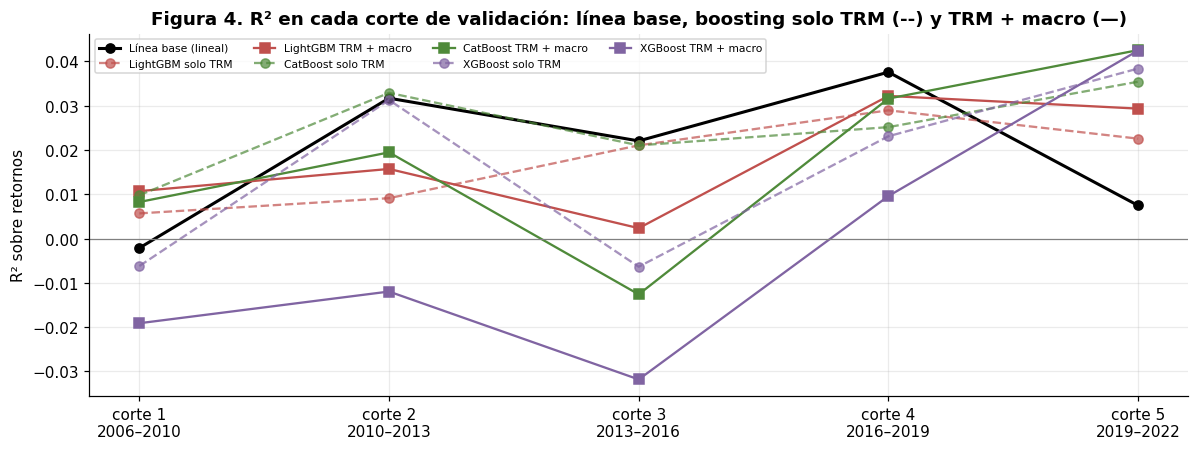

In [8]:
filas = []
for alg in cfg.MODELOS_BOOSTING:
    s, c = resultados[f"{alg} · solo_trm"].set_index("corte"), resultados[f"{alg} · trm_macro"].set_index("corte")
    filas.append({"algoritmo": alg,
                  "delta_rmse_pesos_media": (c["rmse_pesos"] - s["rmse_pesos"]).mean(),
                  "delta_r2_media": (c["r2_retornos"] - s["r2_retornos"]).mean(),
                  "cortes_donde_macro_baja_rmse": int((c["rmse_pesos"] < s["rmse_pesos"]).sum()),
                  **{f"delta_r2_corte_{i}": (c["r2_retornos"] - s["r2_retornos"]).loc[i] for i in range(1, 6)}})
t6 = pd.DataFrame(filas).set_index("algoritmo")
t6["veredicto"] = np.where(t6["cortes_donde_macro_baja_rmse"] >= 4, "aportan",
                           np.where(t6["cortes_donde_macro_baja_rmse"] >= 2, "aporte inestable", "no aportan"))
guardar_tabla(t6, "tab06_aporte_macro")
display(t6)

r2 = por_corte["r2_retornos"].unstack("corte")
fig, eje = plt.subplots(figsize=(11, 4.2))
x = np.arange(1, 6)
eje.plot(x, r2.loc["Línea base (lineal)"], "k-o", lw=2, label="Línea base (lineal)")
for alg, c in zip(cfg.MODELOS_BOOSTING, COLORES[1:]):
    eje.plot(x, r2.loc[f"{alg} · solo_trm"], "--o", color=c, alpha=0.7, label=f"{alg} solo TRM")
    eje.plot(x, r2.loc[f"{alg} · trm_macro"], "-s", color=c, label=f"{alg} TRM + macro")
eje.axhline(0, color="grey", lw=0.8)
eje.set_xticks(x, [f"corte {i}\n{tcortes.loc[i, 'valida_desde'].year}–{tcortes.loc[i, 'valida_hasta'].year}" for i in x])
eje.set(ylabel="R² sobre retornos",
        title="Figura 4. R² en cada corte de validación: línea base, boosting solo TRM (--) y TRM + macro (—)")
eje.legend(fontsize=7, ncol=4)
fig.tight_layout(); guardar_figura(fig, "fig04_validacion_por_corte"); plt.show()

**Lectura de la Tabla 6 y la Figura 4, la respuesta preliminar a la pregunta de investigación:**
- **Las variables macro no mejoran la predicción de forma confiable en ningún algoritmo:**
  - **LightGBM** cumple formalmente la regla: la versión con macro tiene menor RMSE en 4 de 5 cortes. Pero las mejoras son de **0,03 a 0,08 pesos** y en el corte 3 empeora 0,24, así que **en promedio el RMSE sube** (+0,008) y el R² apenas cambia (+0,0006). Es un aporte nulo en la práctica.
  - **CatBoost** mejora en 2 de 5 cortes: aporte inestable, con el R² bajando 0,007 en promedio.
  - **XGBoost** mejora en 1 de 5: las macro lo empeoran (el R² baja 0,018).
- **El patrón por corte es el que anticipó el EDA:**
  - **Corte 5 (2019–2022, COVID y choque petrolero):** las macro mejoran a **los tres** algoritmos (Δ R² de +0,004 a +0,007). E10 mostró que el Brent pesa en los choques.
  - **Corte 3 (2013–2016, caída del petróleo):** las macro **empeoran a los tres** (Δ R² de −0,019 a −0,034). La explicación está en E6: antes de 2014 la relación con el Brent era casi nula, así que un modelo entrenado con 2003–2013 no pudo aprender una relación que apareció justo en el periodo de validación.

  **Una relación que cambia con el tiempo no se puede aprender del pasado**, y ese es el mecanismo del resultado negativo.
- **Qué algoritmo aprovecha mejor las macro** (segunda parte de la pregunta de la Entrega 1): LightGBM es el que menos se perjudica, pero ninguno las aprovecha de forma apreciable.

## 8. Estabilidad de los hiperparámetros elegidos

In [9]:
hp = pd.concat({k: v.set_index("corte") for k, v in hiper.items()}, names=["configuracion", "corte"])
guardar_tabla(hp, "tab05d_hiperparametros_por_corte")
for k, v in hiper.items():
    print(f"\n{k}"); display(v.set_index("corte"))


LightGBM · solo_trm


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree
corte,,,,,,,,
1,1.0000,0.0000,4,800,200,3,0.0300,0.8000
2,0.6000,1.0000,4,200,100,2,0.0300,0.8000
3,0.8000,5.0000,15,400,200,4,0.0300,0.6000
4,0.6000,0.0000,4,400,200,4,0.0300,0.8000
5,0.6000,1.0000,31,200,200,2,0.0300,0.8000



LightGBM · trm_macro


,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,colsample_bytree
corte,,,,,,,,
1,0.8000,0.0000,4,100,20,3,0.0100,0.6000
2,0.8000,0.0000,4,100,20,3,0.0100,0.6000
3,1.0000,5.0000,31,200,20,3,0.0100,0.6000
4,0.6000,1.0000,31,200,200,2,0.0300,0.8000
5,0.6000,1.0000,31,200,200,2,0.0300,0.8000



CatBoost · solo_trm


...

,subsample,rsm,min_data_in_leaf,learning_rate,l2_leaf_reg,iterations,depth
corte,,,,,,,
1,0.8000,1.0000,200,0.0100,10.0000,100,2
2,0.8000,0.6000,50,0.1000,10.0000,200,4
3,0.8000,1.0000,200,0.0500,5.0000,200,4
4,0.8000,1.0000,20,0.0100,1.0000,200,4
5,0.8000,0.6000,20,0.0300,1.0000,100,6



XGBoost · solo_trm


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
corte,,,,,,,
1,0.8000,0.0000,100,1,2,0.0300,0.6000
2,0.8000,0.0000,400,10,2,0.0100,1.0000
3,0.8000,10.0000,100,1,6,0.0300,0.8000
4,0.8000,0.0000,100,1,2,0.0300,0.6000
5,0.8000,0.0000,100,1,2,0.0300,0.6000



XGBoost · trm_macro


,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
corte,,,,,,,
1,0.8000,0.0000,100,1,2,0.0300,0.6000
2,0.8000,5.0000,100,1,6,0.0500,0.8000
3,0.8000,10.0000,100,1,6,0.0300,0.8000
4,0.8000,10.0000,400,5,4,0.0100,0.6000
5,0.8000,0.0000,100,1,2,0.0300,0.6000


**Lectura:**
- **Los hiperparámetros elegidos son coherentes con una señal débil:** profundidad de 2 en la mayoría de los cortes, tasas de aprendizaje de 0,01 a 0,03 y hojas con muchas observaciones (100 a 200).
- **Cambian bastante entre cortes.** El número de árboles va de 100 a 800 y el de hojas de 4 a 31. No es una falla: cuando casi no hay señal, muchas combinaciones rinden prácticamente igual, y la búsqueda elige entre ellas casi al azar. Por eso no conviene interpretar un valor concreto de un hiperparámetro como "el óptimo".
- **Queda en el informe como resultado de estabilidad (rúbrica 7.4):** la estructura de los modelos elegidos es estable (árboles simples y aprendizaje lento), pero los valores exactos no.

## 9. Contraste de las hipótesis del EDA (H1–H4)

In [10]:
boost = t5.drop(index="Línea base (lineal)")
mejor = boost.sort_values(["rmse_media", "rmse_desv"]).index[0]
lb = t5.loc["Línea base (lineal)"]
vol = tcortes.assign(vol=[100 * dev["y"].iloc[va].std() * np.sqrt(252) for _, va in cortes])["vol"]
corr_vol_error = np.corrcoef(vol, por_corte.loc["Línea base (lineal)", "rmse_pesos"])[0, 1]
hip = pd.DataFrame([
    ["H1", "La línea base logra un R² sobre retornos pequeño y positivo, cercano a 0,03",
     f"R² medio {lb['r2_media']:.4f} ± {lb['r2_desv']:.4f}; positivo en {int(lb['cortes_con_r2_positivo'])} de 5 cortes"],
    ["H2", "Los boosting no superan de forma apreciable a la línea base (Δ R² < 0,005)",
     f"Mejor boosting: {mejor}, R² {boost.loc[mejor, 'r2_media']:.4f} (Δ = {boost.loc[mejor, 'r2_media'] - lb['r2_media']:+.4f}); "
     f"gana en RMSE en {int(boost.loc[mejor, 'cortes_que_gana_a_linea_base_rmse'])} de 5 cortes"],
    ["H3", "Las macro aportan poco y de forma inestable",
     "; ".join(f"{a}: {t6.loc[a, 'veredicto']} ({t6.loc[a, 'cortes_donde_macro_baja_rmse']}/5, Δ R² {t6.loc[a, 'delta_r2_media']:+.4f})" for a in t6.index)],
    ["H4", "El error es mayor en los cortes turbulentos",
     f"Correlación entre volatilidad del corte y RMSE de la línea base: {corr_vol_error:.2f}"],
], columns=["hipótesis", "enunciado (EDA)", "evidencia en validación"]).set_index("hipótesis")
guardar_tabla(hip, "tab05e_hipotesis")
display(hip)
print(f"Mejor configuración de boosting (regla fijada antes): {mejor}")

,enunciado (EDA),evidencia en validación
hipótesis,,
H1,La línea base logra un R² sobre retornos peque...,R² medio 0.0193 ± 0.0165; positivo en 4 de 5 c...
H2,Los boosting no superan de forma apreciable a ...,"Mejor boosting: CatBoost · solo_trm, R² 0.0249..."
H3,Las macro aportan poco y de forma inestable,"LightGBM: aportan (4/5, Δ R² +0.0006); CatBoos..."
H4,El error es mayor en los cortes turbulentos,Correlación entre volatilidad del corte y RMSE...


Mejor configuración de boosting (regla fijada antes): CatBoost · solo_trm


**Lectura del contraste de hipótesis:**

| | Veredicto | Por qué |
|---|---|---|
| **H1** | **Se confirma en parte** | La línea base logra un R² positivo en 4 de 5 cortes, pero su media fuera de muestra (0,019) queda por debajo del 0,03 que el EDA calculó **dentro de muestra**. Es lo esperado: fuera de muestra siempre se predice peor. Falla en la crisis de 2008, donde E10 mostró que la memoria desaparece |
| **H2** | **Se confirma en la práctica, en el límite en los números** | El mejor boosting supera a la línea base en +0,0056 de R², apenas sobre el umbral de 0,005. En pesos es −0,13 de RMSE con un MAE idéntico, frente a una variación de 7 pesos entre periodos. El EDA anticipaba este tamaño exacto: en E9 la única no linealidad era la de `r_trm_l1` (η² 0,032 frente a r² 0,027), una diferencia de 0,005, y eso es lo que el boosting aprovecha |
| **H3** | **Se confirma** | Las macro no aportan de forma confiable en ningún algoritmo; ayudan en el periodo de choques (corte 5) y perjudican donde la relación con el Brent apareció después del entrenamiento (corte 3) |
| **H4** | **Se confirma** | La correlación entre la volatilidad del corte y el RMSE de la línea base es de 0,61. El corte de menor volatilidad (2010–2013) tiene el menor error (≈10 pesos) y el del COVID el mayor (≈29), en todos los modelos |

**Mejor configuración de boosting, elegida con la regla fijada antes: CatBoost solo TRM.** Es la que se interpreta con SHAP en el notebook 06. En el test se evalúan **las 7 configuraciones**, no solo la elegida, para ver si el empate se mantiene fuera de la muestra de desarrollo.

## 10. Auditoría antes de congelar
Antes de fijar la configuración se comprueba, con pruebas automáticas, que el flujo cumple lo que se afirma.

In [11]:
auditoria = {}
auditoria["solo desarrollo en este notebook"] = bool((dev["muestra"] == "desarrollo").all())
auditoria["validación posterior al entrenamiento con gap ≥ 5"] = all(tr.max() + cfg.GAP < va.min() for tr, va in cortes)
auditoria["mismos cortes para los 7 modelos"] = all(
    (predicciones[k]["fecha"].to_numpy() == predicciones["Línea base (lineal)"]["fecha"].to_numpy()).all() for k in predicciones)
auditoria["predicciones sin valores faltantes"] = all(p["yhat"].notna().all() for p in predicciones.values())
# El escalado de la línea base se ajusta dentro de cada corte: su media aprendida debe ser la del entrenamiento del corte
from src.modelos import crear_modelo
tr0 = cortes[0][0]
lin = crear_modelo("lineal").fit(dev[cfg.VARS_TRM].iloc[tr0], dev["y"].iloc[tr0])
auditoria["escalador ajustado solo con el entrenamiento del corte"] = bool(
    np.allclose(lin.named_steps["escala"].mean_, dev[cfg.VARS_TRM].iloc[tr0].mean()))
auditoria["la métrica reproduce el RMSE de copiar la TRM de hoy"] = bool(np.isclose(
    metricas(dev["y"], np.zeros(len(dev)), dev["trm"])["rmse_pesos"], np.sqrt(np.mean((dev["trm_sig"] - dev["trm"]) ** 2))))
aud = pd.Series(auditoria, name="superada")
assert aud.all(), aud[~aud]
guardar_tabla(aud.to_frame(), "tab05f_auditoria")
display(aud.to_frame())

,superada
solo desarrollo en este notebook,True
validación posterior al entrenamiento con gap ≥ 5,True
mismos cortes para los 7 modelos,True
predicciones sin valores faltantes,True
escalador ajustado solo con el entrenamiento del corte,True
la métrica reproduce el RMSE de copiar la TRM de hoy,True


## 11. Modelos finales y congelamiento
Los 7 modelos se reentrenan con **todo** el desarrollo. Los boosting repiten la búsqueda interna sobre el desarrollo completo. Se guardan junto con la configuración elegida, y desde aquí **no se vuelve a elegir nada**: el notebook 06 carga estos archivos, verifica su huella y abre el test una sola vez.

In [12]:
finales, config_modelos = {}, {}
finales["Línea base (lineal)"], _ = ajustar_final(dev, cfg.VARS_TRM, "lineal")
config_modelos["Línea base (lineal)"] = {"algoritmo": "lineal", "variables": cfg.VARS_TRM, "hiperparametros": {}}
for nombre, (algoritmo, variables) in CONFIGS.items():
    finales[nombre], params = ajustar_final(dev, variables, algoritmo)
    config_modelos[nombre] = {"algoritmo": algoritmo, "variables": variables,
                              "hiperparametros": {k: (float(v) if isinstance(v, (np.floating, float)) else int(v)
                                                      if isinstance(v, (np.integer, int)) else v) for k, v in params.items()}}
joblib.dump(finales, cfg.MODELOS / "modelos_finales.joblib")

md5 = lambda ruta: hashlib.md5(Path(ruta).read_bytes()).hexdigest()
contenido = {
    "semilla": cfg.SEMILLA, "periodo": [cfg.FECHA_INICIO, cfg.FECHA_FIN],
    "md5_dataset": md5(cfg.DATA_PROC / "dataset.csv"),
    "particion": json.loads((cfg.DATA_PROC / "particion.json").read_text()),
    "validacion": {"cortes_externos": cfg.N_CORTES_EXTERNOS, "cortes_internos": cfg.N_CORTES_INTERNOS,
                   "gap": cfg.GAP, "combinaciones_busqueda": cfg.N_BUSQUEDA},
    "regla_mejor_modelo": "menor RMSE medio en validación entre las 6 configuraciones de boosting",
    "mejor_boosting": mejor,
    "modelos": config_modelos,
    # Huella funcional de los modelos: MD5 de sus predicciones sobre el desarrollo (el .joblib cambia de bytes
    # entre corridas por metadatos internos aunque el modelo sea idéntico; las predicciones no).
    "huella_predicciones_desarrollo": {k: hashlib.md5(np.round(m.predict(dev[config_modelos[k]["variables"]]), 12)
                                                      .tobytes()).hexdigest() for k, m in finales.items()},
}
huella = hashlib.md5(json.dumps(contenido, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
cfg.CONFIG_CONGELADA.write_text(json.dumps({"md5_contenido": huella, **contenido}, indent=2, ensure_ascii=False),
                                encoding="utf-8")
print(f"Congelado: config_congelada.json (MD5 del contenido {huella}) y models/modelos_finales.joblib")
display(pd.DataFrame({k: v["hiperparametros"] for k, v in config_modelos.items() if v["hiperparametros"]}))

Congelado: config_congelada.json (MD5 del contenido 0e4e09244ce880576a14400d9d91e75c) y models/modelos_finales.joblib


,LightGBM · solo_trm,LightGBM · trm_macro,CatBoost · solo_trm,CatBoost · trm_macro,XGBoost · solo_trm,XGBoost · trm_macro
subsample,0.6000,0.6000,0.8000,1.0000,1.0000,0.8000
reg_lambda,1.0000,1.0000,NaN,NaN,1.0000,0.0000
num_leaves,4.0000,31.0000,NaN,NaN,NaN,NaN
n_estimators,200.0000,200.0000,NaN,NaN,100.0000,400.0000
min_child_samples,100.0000,200.0000,NaN,NaN,NaN,NaN
max_depth,2.0000,2.0000,NaN,NaN,2.0000,2.0000
learning_rate,0.0300,0.0300,0.0300,0.0300,0.0500,0.0100
colsample_bytree,0.8000,0.8000,NaN,NaN,0.6000,1.0000
rsm,NaN,NaN,0.8000,1.0000,NaN,NaN
min_data_in_leaf,NaN,NaN,50.0000,100.0000,NaN,NaN


## 12. Prueba de robustez: ¿el resultado depende del método de ajuste? (Optuna)
Pregunta que aparecerá en la sustentación: *"¿y si hubieran ajustado mejor los hiperparámetros?"*. Se repite la validación anidada cambiando **solo la estrategia de búsqueda** del bucle interno, de **aleatoria** (`RandomizedSearchCV`) a **bayesiana** (Optuna, con el muestreador TPE, que aprende de los intentos anteriores y se concentra en las zonas prometedoras). Los valores posibles de cada hiperparámetro son **los mismos** de la Tabla 4, los cortes son los mismos y la semilla también. Se prueban dos presupuestos: **15 intentos**, el mismo de la búsqueda aleatoria, y **50 intentos**, para ver si buscar más ayuda.

**Regla fijada antes de correrlo:** si Optuna cambia el RMSE medio en menos de **0,5 pesos** en todas las configuraciones, el resultado es robusto al método de ajuste y **la configuración congelada no se modifica**. Esta sección no toca el test ni `config_congelada.json`.

In [13]:
from joblib import Parallel, delayed
from src.modelos import evaluar_walk_forward_optuna

t0 = time.perf_counter()
tareas = [(nombre, n) for nombre in CONFIGS for n in (15, 50)]
salidas = Parallel(n_jobs=-1)(delayed(evaluar_walk_forward_optuna)(dev, CONFIGS[nombre][1], CONFIGS[nombre][0], cortes, n)
                             for nombre, n in tareas)
print(f"Optuna en validación anidada: {time.perf_counter() - t0:.0f} s")

filas = []
for (nombre, n), r in zip(tareas, salidas):
    filas.append({"configuracion": nombre, "busqueda": f"Optuna ({n} intentos)",
                  "rmse_media": r["rmse_pesos"].mean(), "r2_media": r["r2_retornos"].mean()})
for nombre in CONFIGS:
    filas.append({"configuracion": nombre, "busqueda": "Aleatoria (15 intentos)",
                  "rmse_media": t5.loc[nombre, "rmse_media"], "r2_media": t5.loc[nombre, "r2_media"]})
rob = pd.DataFrame(filas).pivot(index="configuracion", columns="busqueda", values=["rmse_media", "r2_media"])
for n in (15, 50):
    rob[("delta_rmse", f"Optuna {n} − aleatoria")] = rob[("rmse_media", f"Optuna ({n} intentos)")] - rob[("rmse_media", "Aleatoria (15 intentos)")]
rob = rob.loc[list(CONFIGS)]
guardar_tabla(rob, "tab05g_robustez_optuna")
display(rob.round(4))

max_cambio = rob["delta_rmse"].abs().max().max()
mejor_optuna = rob[("rmse_media", "Optuna (50 intentos)")].idxmin()
print(f"Mayor cambio de RMSE medio por usar Optuna: {max_cambio:.3f} pesos (umbral 0,5)")
print(f"Mejor configuración con Optuna (50 intentos): {mejor_optuna} | congelada: {mejor}")
print("Veredicto:", "ROBUSTO: la configuración congelada se mantiene" if max_cambio < 0.5
      else "NO ROBUSTO: discutir con el equipo antes de abrir el test")

Optuna en validación anidada: 63 s


rmse_media                       \
busqueda             Aleatoria (15 intentos) Optuna (15 intentos)   
configuracion                                                       
LightGBM · solo_trm                  20.7658              20.7623   
LightGBM · trm_macro                 20.7742              20.7843   
CatBoost · solo_trm                  20.7064              20.7129   
CatBoost · trm_macro                 20.7679              20.6770   
XGBoost · solo_trm                   20.8052              20.7309   
XGBoost · trm_macro                  20.9382              20.7195   

                                                         r2_media  \
busqueda             Optuna (50 intentos) Aleatoria (15 intentos)   
configuracion                                                       
LightGBM · solo_trm               20.7610                  0.0175   
LightGBM · trm_macro              20.7644                  0.0181   
CatBoost · solo_trm               20.7049                  0.0249   
CatBoost · trm_macro              20.6968                  0.0179   
XGBoost · solo_trm                20.7352                  0.0160   
XGBoost · trm_macro               20.8083                 -0.0022   

                                                                \
busqueda             Optuna (15 intentos) Optuna (50 intentos)   
configuracion                                                    
LightGBM · solo_trm                0.0208               0.0201   
LightGBM · trm_macro               0.0180               0.0192   
CatBoost · solo_trm                0.0244               0.0254   
CatBoost · trm_macro               0.0282               0.0272   
XGBoost · solo_trm                 0.0221               0.0221   
XGBoost · trm_macro                0.0215               0.0133   

                                delta_rmse                        
busqueda             Optuna 15 − aleatoria Optuna 50 − aleatoria  
configuracion                                                     
LightGBM · solo_trm                -0.0035               -0.0048  
LightGBM · trm_macro                0.0101               -0.0098  
CatBoost · solo_trm                 0.0065               -0.0015  
CatBoost · trm_macro               -0.0909               -0.0711  
XGBoost · solo_trm                 -0.0744               -0.0700  
XGBoost · trm_macro                -0.2186               -0.1299

Mayor cambio de RMSE medio por usar Optuna: 0.219 pesos (umbral 0,5)
Mejor configuración con Optuna (50 intentos): CatBoost · trm_macro | congelada: CatBoost · solo_trm
Veredicto: ROBUSTO: la configuración congelada se mantiene


**Lectura de la prueba de robustez:**
- **Veredicto: el resultado es robusto al método de ajuste.** El mayor cambio de RMSE medio por usar Optuna es de **0,22 pesos** (XGBoost TRM + macro), por debajo del umbral de 0,5. En las otras cinco configuraciones el cambio es menor a 0,1 pesos. Con 50 intentos en lugar de 15 no se gana nada adicional: el RMSE sigue entre 20,70 y 20,81. **Buscar más o mejor no mueve el resultado, porque el límite es la señal de los datos, no el ajuste.** Según la regla fijada, la configuración congelada se mantiene (su MD5 no cambió).
- **Dos matices que se reportan tal cual:**
  1. **El orden entre configuraciones casi empatadas no es estable.** Con Optuna, la de menor RMSE pasa a ser CatBoost TRM + macro (20,697) en lugar de CatBoost solo TRM (20,705): **0,008 pesos** de diferencia, menos de un centavo. No significa que las macro ahora aporten; significa que esas dos configuraciones están empatadas y que "el mejor modelo" es, en la práctica, un empate entre varias. Por eso en el test se evalúan las 7, no solo la elegida.
  2. **El mal resultado de XGBoost TRM + macro dependía en parte de la búsqueda.** Con la búsqueda aleatoria su R² era −0,002; con Optuna sube a 0,013–0,022, cerca de los demás. La conclusión de H3 se matiza: con XGBoost, las macro no "empeoran" el modelo, simplemente **no lo mejoran** (con Optuna 50 sigue peor que su versión solo TRM: 20,81 frente a 20,74).
- **Para el informe:** "El ajuste de hiperparámetros se verificó con dos métodos, búsqueda aleatoria y optimización bayesiana con Optuna, y con dos presupuestos; las diferencias son menores a 0,22 pesos. El techo de desempeño lo pone la débil señal de la TRM diaria, no el ajuste de los modelos." 

## Qué llevar al informe
- **Figura 2** (`fig02_pipeline.png`): el flujo completo con la razón anti-fuga de cada etapa (7.2).
- **Tabla de cambios frente a la Entrega 1** (`tab05b_cambios_entrega1.csv`) con su motivo (7.3, "qué se modificó").
- **Tabla 4** (`tab04b_espacios_busqueda.csv`): espacios de búsqueda justificados con el EDA (7.3, "ajuste bien fundamentado").
- **Tabla 5** (`tab05_validacion.csv`): media ± desviación de las 7 configuraciones (7.4, "resultados con su variabilidad"). **Mensaje central:** todos empatan dentro de ±0,25 pesos, frente a 7 pesos de variación entre periodos.
- **Tabla 6 y Figura 4** (`tab06_aporte_macro.csv`, `fig04_validacion_por_corte.png`): las macro no aportan de forma confiable. Ayudan en el choque de 2019–2022 y perjudican en 2013–2016, porque la relación con el Brent cambió en el tiempo.
- **Prueba de robustez con Optuna** (`tab05g_robustez_optuna.csv`): cambiar de búsqueda aleatoria a bayesiana, o de 15 a 50 intentos, mueve el RMSE menos de 0,22 pesos; el orden entre configuraciones casi empatadas cambia, lo que confirma que son un empate.
- **Contraste de hipótesis** (`tab05e_hipotesis.csv`): H1 en parte, H2, H3 y H4 confirmadas, todas anticipadas por el EDA antes de entrenar.
- **Auditoría** (`tab05f_auditoria.csv`) y **congelamiento** (`config_congelada.json` con MD5 de su contenido y huella de las predicciones de cada modelo; `models/modelos_finales.joblib`).
- **Respuesta preliminar a la pregunta de investigación:** en validación, las variables macroeconómicas **no mejoran** la predicción diaria de la TRM frente a usar solo su historia, en ninguno de los tres boosting. La poca señal que existe está en el movimiento del día anterior, y un boosting solo la aprovecha ligeramente mejor que la regresión lineal (−0,13 pesos de RMSE).